<a href="https://colab.research.google.com/github/Duman18/portfolio-risk-engine/blob/main/04_stress_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Duman18/portfolio-risk-engine/refs/heads/main/returns.csv"
returns = pd.read_csv(url, index_col=0, parse_dates=True)

weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
port_returns = returns.dot(weights)
V = 1_000_000

var99 = -np.percentile(port_returns, 1) * V
print("Benchmark, 1-day 99% Historical VaR: HK$", round(var99))

Benchmark, 1-day 99% Historical VaR: HK$ 35116


In [2]:
worst_day = port_returns.idxmin()
worst_ret = port_returns.min()

print("Worst day:", worst_day.date())
print("Return:", round(worst_ret * 100, 2), "%")
print("Loss: HK$", round(-worst_ret * V))
print("Times bigger than 99% VaR:", round(-worst_ret * V / var99, 1))

Worst day: 2025-04-07
Return: -13.29 %
Loss: HK$ 132854
Times bigger than 99% VaR: 3.8


In [3]:
scenarios = {
    "2018 trade war (Jan–Oct 2018)":   ("2018-01-26", "2018-10-30"),
    "COVID crash (Jan–Mar 2020)":       ("2020-01-20", "2020-03-23"),
    "2022 HK sell-off (Jan–Oct 2022)":  ("2022-01-01", "2022-10-31"),
    "Tariff shock (Apr 2025)":          ("2025-04-02", "2025-04-09"),
}

rows = []
for name, (start, end) in scenarios.items():
    r = port_returns.loc[start:end]
    total = (1 + r).prod() - 1
    rows.append([name, len(r), total * 100, -total * V, r.min() * 100, -total * V / var99])

stress = pd.DataFrame(rows, columns=[
    "Scenario", "Trading days", "Total return %", "Loss HK$", "Worst day %", "× 99% VaR"
]).set_index("Scenario").round(1)
stress

,Trading days,Total return %,Loss HK$,Worst day %,× 99% VaR
Scenario,,,,,
2018 trade war (Jan–Oct 2018),186,-26.0,259730.9,-5.3,7.4
COVID crash (Jan–Mar 2020),44,-23.3,232684.6,-4.5,6.6
2022 HK sell-off (Jan–Oct 2022),204,-35.7,357229.8,-7.0,10.2
Tariff shock (Apr 2025),5,-14.8,147957.6,-13.3,4.2


Maximum drawdown: -48.5 %
Bottom date: 2022-10-28


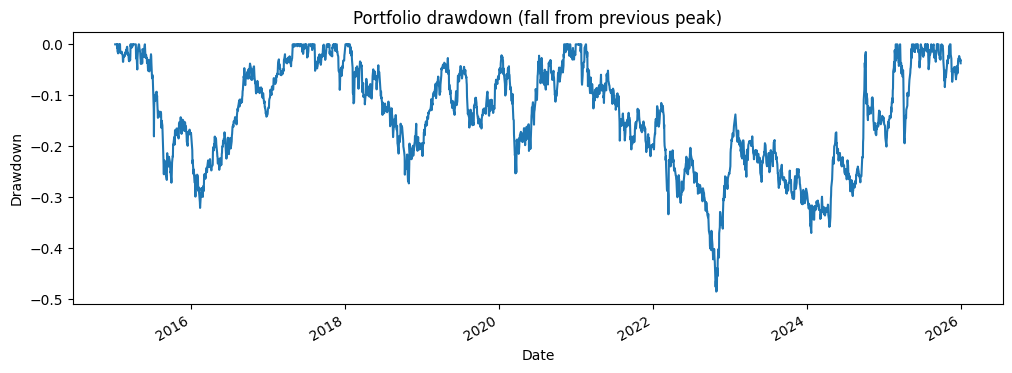

In [4]:
value = (1 + port_returns).cumprod() * V
peak = value.cummax()
drawdown = value / peak - 1

max_dd = drawdown.min()
print("Maximum drawdown:", round(max_dd * 100, 1), "%")
print("Bottom date:", drawdown.idxmin().date())

drawdown.plot(figsize=(12,4), title="Portfolio drawdown (fall from previous peak)")
plt.ylabel("Drawdown")
plt.savefig("drawdown_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
shocks = pd.Series({
    "0005.HK": -0.15,
    "0388.HK": -0.20,
    "0700.HK": -0.30,
    "1299.HK": -0.15,
    "2800.HK": -0.20,
})

port_shock = (shocks[returns.columns] * weights).sum()
print("Portfolio return in scenario:", round(port_shock * 100, 1), "%")
print("Loss: HK$", round(-port_shock * V))
print("Times bigger than 99% VaR:", round(-port_shock * V / var99, 1))

Portfolio return in scenario: -20.0 %
Loss: HK$ 200000
Times bigger than 99% VaR: 5.7


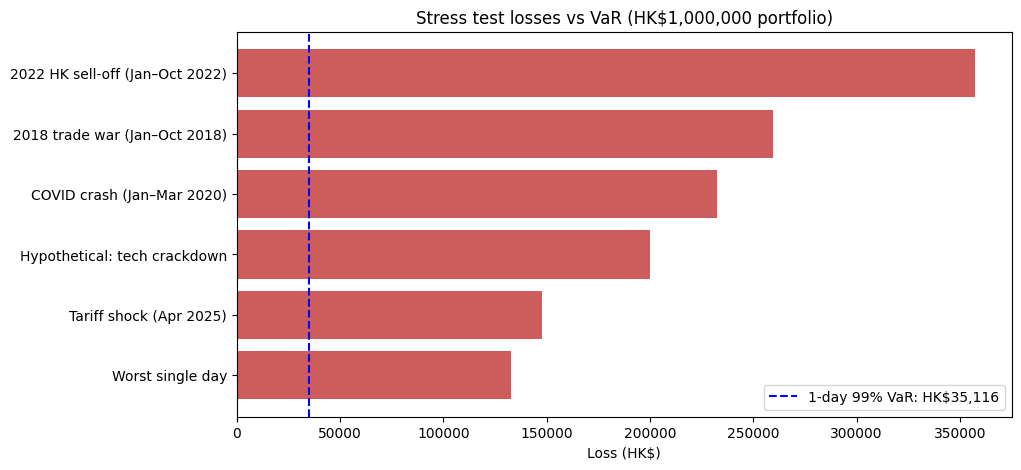

In [6]:
losses = stress["Loss HK$"].copy()
losses["Worst single day"] = -worst_ret * V
losses["Hypothetical: tech crackdown"] = -port_shock * V
losses = losses.sort_values()

plt.figure(figsize=(10,5))
plt.barh(losses.index, losses.values, color="indianred")
plt.axvline(var99, color="blue", linestyle="--", label=f"1-day 99% VaR: HK${var99:,.0f}")
plt.title("Stress test losses vs VaR (HK$1,000,000 portfolio)")
plt.xlabel("Loss (HK$)")
plt.legend()
plt.savefig("stress_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

| Scenario | Loss (HK$) | × 99% VaR |
|---|---|---|
| Worst single day (2025-04-07) | 132,854 | 3.8× |
| 2018 trade war (Jan–Oct 2018) | 259,731 | 7.4× |
| COVID crash (Jan–Mar 2020) | 232,685 | 6.6× |
| 2022 HK sell-off (Jan–Oct 2022) | 357,230 | 10.2× |
| Tariff shock (Apr 2025) | 147,958 | 4.2× |
| Hypothetical tech crackdown | 200,000 | 5.7× |

Maximum drawdown: -48.5% (lowest point on 2022-10-28).

### Key findings

1. The worst single day lost about 3.8× the 1-day 99% VaR, so VaR does not describe how bad an extreme day can be.
2. Crisis periods caused losses of 4.2× to 10.2× the 1-day VaR, because VaR only looks one day ahead.
3. VaR should be used together with stress tests and drawdown analysis, not on its own.

Note: crisis periods use approximate start and end dates.